# Fraude con IA: dependencia de controles y resiliencia

## tl;dr

Dos controles con buenas tasas marginales pueden compartir fallos. En este generador, la tasa conjunta de escape varía de **0,96% a 8%** al aumentar la fracción de fallo compartido; la economía de añadir la segunda capa cambia de signo. Es álgebra del escenario, no rendimiento de proveedores.

Una simulación separada compara aprobar errores, enviarlos a revisión y diferirlos para reintentar. El replay reduce demanda manual a cambio de casos pendientes y más llamadas; no se mide pérdida evitada ni se demuestra que una ruta sea adecuada para producción.

Solo datos sintéticos; no se llama a ninguna API. Fuentes y protocolos comerciales en [PROVIDERS.md](PROVIDERS.md), arquitectura en [ARCHITECTURES.md](ARCHITECTURES.md).

## Context & Methods

Cuaderno experimental para equipos de fraude, modelos y operaciones. Dos preguntas: ¿cuánto cambia el riesgo si controles fallan juntos? ¿qué ocurre con la revisión al caer una dependencia?

### Key Assumptions

La mezcla compartida es un parámetro de generación, **no** el coeficiente de correlación de Pearson. Marginales fijas, ataques idénticamente distribuidos dentro del escenario y detección que evita toda pérdida por fraude. El costo monetario es ilustrativo COP por solicitud; no son precios comerciales ni pérdida bancaria estimada. Los legítimos tienen falsas alertas independientes en la sección económica. No se identifican eficacia causal, tasas genuinas reales ni desempeño ante nuevos ataques.

La cola es FIFO discreta diaria; revisión consume una unidad/caso y es perfecta solo como resolución administrativa del estado. No representa adjudicación de fraude ni SLA. La ruta diferida supone posibilidad de replay y llamadas sin límite, condición que debe probarse antes de adoptarla.

## Data

Generador propio, semillas explícitas, sin PII. En el primer experimento se generan directamente intentos de fraude para estimar tasas condicionales. La prevalencia de originación se introduce por separado en el costo. El segundo experimento contiene 14 cohortes de 1.000 casos y una caída con 40% de errores durante tres días, frente a 1% en el resto. Estos parámetros son supuestos de estrés.

In [1]:
%matplotlib inline
import json
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
SEED = 20261023
N_ATTACKS = 200_000
MISS_A, MISS_B = .12, .08
SHARED_GRID = np.linspace(0, 1, 9)

No event loop hook running.


### 1. Derivar el fallo conjunto

Sea $Z\sim Bernoulli(r)$ un selector. Cuando $Z=1$, ambos controles usan el mismo uniforme $U$: $A=1[U<m_A]$, $B=1[U<m_B]$. Cuando $Z=0$, usan uniformes independientes. $A=1$ significa que el ataque escapa del control A.

Por probabilidad total:

$$j(r)=P(A=1,B=1\mid F)=r\min(m_A,m_B)+(1-r)m_A m_B.$$

Así, $j(0)=m_A m_B$ y $j(1)=\min(m_A,m_B)$. Esta construcción tiene dependencia positiva; no explora toda dependencia posible. Las cotas de Fréchet son $\max(0,m_A+m_B-1)\le j\le\min(m_A,m_B)$.

In [2]:
def joint_escape(shared, ma=MISS_A, mb=MISS_B):
    shared = np.asarray(shared)
    return shared * min(ma, mb) + (1-shared) * ma * mb

assert np.isclose(joint_escape(0), MISS_A*MISS_B)
assert np.isclose(joint_escape(1), min(MISS_A, MISS_B))
assert np.all(np.diff(joint_escape(SHARED_GRID)) >= 0)
print({"independiente": float(joint_escape(0)), "compartido": float(joint_escape(1)),
       "factor_extremos": float(joint_escape(1)/joint_escape(0))})

{'independiente': 0.0096, 'compartido': 0.08, 'factor_extremos': 8.333333333333334}


### 2. Simular sobre ataques pareados

Se reutilizan uniformes en el grid para reducir ruido de comparación. Cada fila tiene 200.000 intentos; las filas no son muestras independientes entre sí. Los intervalos Wilson son marginales por escenario, no simultáneos.

In [3]:
rng = np.random.default_rng(SEED)
selector, common, ua, ub = rng.random((4, N_ATTACKS))
rows=[]
for shared in SHARED_GRID:
    use_common = selector < shared
    a = np.where(use_common, common, ua) < MISS_A
    b = np.where(use_common, common, ub) < MISS_B
    escaped = a & b
    phat = escaped.mean()
    z, n = 1.96, len(escaped)
    center = (phat + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(phat*(1-phat)/n+z*z/(4*n*n))/(1+z*z/n)
    rows.append(dict(shared_fraction=shared, miss_a=a.mean(), miss_b=b.mean(),
                     empirical=phat, exact=float(joint_escape(shared)),
                     lower=center-half, upper=center+half))
control_table=pd.DataFrame(rows)
display(control_table.round(5))

,shared_fraction,miss_a,miss_b,empirical,exact,lower,upper
0,0.000,0.12053,0.08041,0.00966,0.0096,0.00924,0.01010
1,0.125,0.12032,0.08023,0.01839,0.0184,0.01781,0.01899
2,0.250,0.12017,0.07986,0.02692,0.0272,0.02622,0.02764
3,0.375,0.12016,0.08003,0.03587,0.0360,0.03506,0.03669
4,0.500,0.12046,0.08001,0.04497,0.0448,0.04407,0.04589
5,0.625,0.12064,0.07991,0.05372,0.0536,0.05275,0.05472
6,0.750,0.12048,0.08005,0.06241,0.0624,0.06136,0.06348
7,0.875,0.12017,0.08010,0.07122,0.0712,0.07010,0.07235
8,1.000,0.11958,0.07978,0.07978,0.0800,0.07860,0.08097


### 3. Contrastar las marginales y la fórmula

La comprobación compara el generador con la expresión exacta y verifica las marginales. Es un chequeo de implementación dentro de una familia de escenarios, no validación de un detector.

In [4]:
assert np.max(np.abs(control_table.miss_a-MISS_A)) < .004
assert np.max(np.abs(control_table.miss_b-MISS_B)) < .004
assert np.max(np.abs(control_table.empirical-control_table.exact)) < .003
print("Marginales y escape conjunto concuerdan con el generador dentro de tolerancias predefinidas.")

Marginales y escape conjunto concuerdan con el generador dentro de tolerancias predefinidas.


### 4. Ver el hueco de independencia

El producto marginal sería constante. La curva revela qué parte de la protección adicional se pierde al compartir la vía de fallo.

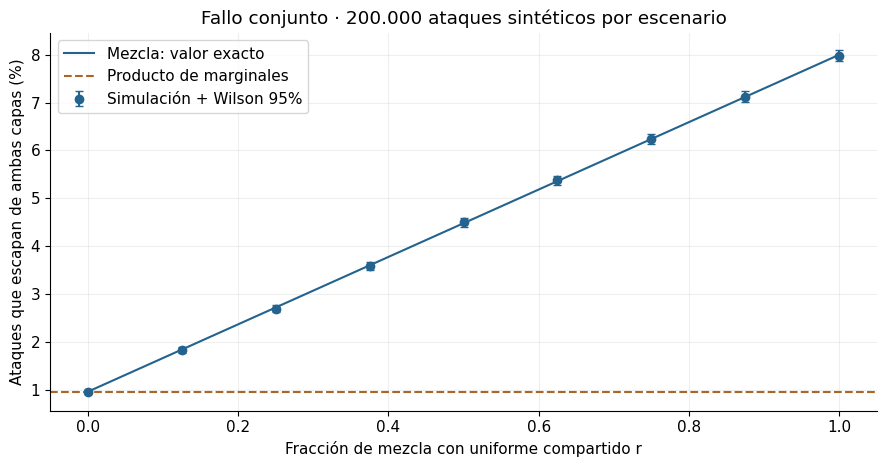

In [5]:
fig, ax = plt.subplots()
ax.plot(control_table.shared_fraction, 100*control_table.exact, label="Mezcla: valor exacto", color="#24638e")
ax.errorbar(control_table.shared_fraction, 100*control_table.empirical,
            yerr=[100*(control_table.empirical-control_table.lower),
                  100*(control_table.upper-control_table.empirical)],
            fmt="o", color="#24638e", capsize=3, label="Simulación + Wilson 95%")
ax.axhline(100*MISS_A*MISS_B, ls="--", color="#ab6524", label="Producto de marginales")
ax.set(xlabel="Fracción de mezcla con uniforme compartido r", ylabel="Ataques que escapan de ambas capas (%)",
       title="Fallo conjunto · 200.000 ataques sintéticos por escenario")
ax.legend(); fig.tight_layout(); plt.show()

### 5. Traducir señales a pérdida y fricción

Para una política cuya tasa de escape es $j$, costo de controles $c$ y tasa de falsa alerta $h$, usamos

$$C=\pi L j+c+(1-\pi)fh.$$

Es un caso especial del motor existente con prevención perfecta de ataques detectados y costo de fricción $f$ por legítimo alertado. Para A sola, $j=m_A$. Para ambas capas, $h=h_A+h_B-h_Ah_B$ bajo independencia **solo de falsas alertas genuinas**, supuesto separado de la mezcla de fraude. Se compara el mismo universo de solicitudes, sin restricción de capacidad en esta sección.

In [6]:
PREVALENCE, SEVERITY = .01, 2_000_000.0
COST_A, COST_B, FRICTION = 300.0, 1_000.0, 3_000.0
FPR_A, FPR_B = .02, .03
fpr_both = FPR_A + FPR_B - FPR_A*FPR_B
cost_a = PREVALENCE*SEVERITY*MISS_A + COST_A + (1-PREVALENCE)*FRICTION*FPR_A
control_table["cost_both_cop"] = PREVALENCE*SEVERITY*control_table.exact + COST_A+COST_B + (1-PREVALENCE)*FRICTION*fpr_both
control_table["saving_cop"] = cost_a-control_table.cost_both_cop
independence_saving=float(control_table.saving_cop.iloc[0])
shared_saving=float(control_table.saving_cop.iloc[-1])
assert independence_saving > 0 > shared_saving
display(control_table[["shared_fraction", "cost_both_cop", "saving_cop"]].round(2))
print({"costo_A_COP_por_caso":cost_a})

{'costo_A_COP_por_caso': 2759.4}


,shared_fraction,cost_both_cop,saving_cop
0,0.00,1638.72,1120.68
1,0.12,1814.72,944.68
2,0.25,1990.72,768.68
3,0.38,2166.72,592.68
4,0.50,2342.72,416.68
5,0.62,2518.72,240.68
6,0.75,2694.72,64.68
7,0.88,2870.72,-111.32
8,1.00,3046.72,-287.32


### 6. Umbral económico de dependencia

La segunda capa se justifica en este cálculo solo si

$$\pi L[m_A-j(r)]>c_B+(1-\pi)f(h_{AB}-h_A).$$

El umbral depende de prevalencia, severidad, fricción y precio supuesto. No usar este umbral para elegir un proveedor sin datos propios y eficacia de intervención estimada.

In [7]:
extra_cost = COST_B + (1-PREVALENCE)*FRICTION*(fpr_both-FPR_A)
slope = min(MISS_A,MISS_B)-MISS_A*MISS_B
critical_shared = (MISS_A-MISS_A*MISS_B-extra_cost/(PREVALENCE*SEVERITY))/slope
assert np.isclose(PREVALENCE*SEVERITY*(MISS_A-joint_escape(critical_shared)), extra_cost)
print({"r_critico_en_este_escenario": round(float(critical_shared),6),
       "ahorro_independiente_COP":round(independence_saving,2),
       "ahorro_fallo_compartido_COP":round(shared_saving,2)})

{'r_critico_en_este_escenario': 0.795939, 'ahorro_independiente_COP': 1120.68, 'ahorro_fallo_compartido_COP': -287.32}


### 7. Comparar el costo de añadir una capa

El eje vertical expresa ahorro respecto a A sola, incluyendo precio y fricción. Un valor negativo es un costo adicional.

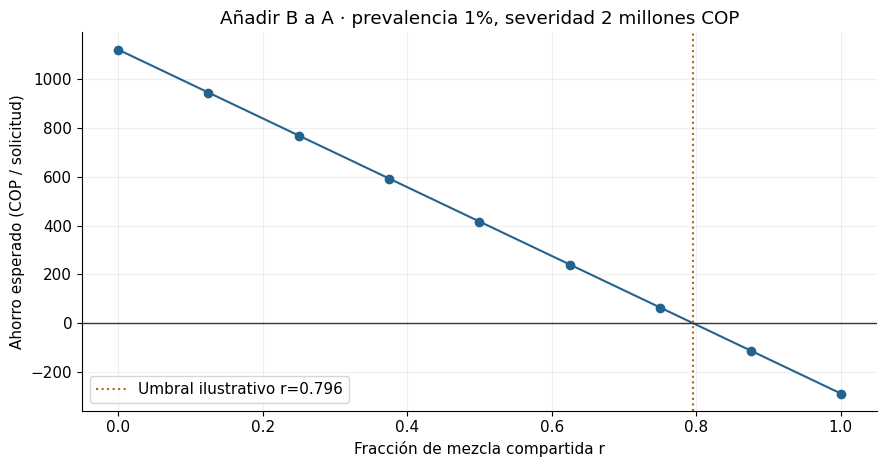

In [8]:
fig, ax=plt.subplots()
ax.plot(control_table.shared_fraction,control_table.saving_cop, marker="o",color="#24638e")
ax.axhline(0,color="#333333",lw=1)
ax.axvline(critical_shared,ls=":",color="#ab6524",label=f"Umbral ilustrativo r={critical_shared:.3f}")
ax.set(xlabel="Fracción de mezcla compartida r",ylabel="Ahorro esperado (COP / solicitud)",
       title="Añadir B a A · prevalencia 1%, severidad 2 millones COP")
ax.legend();fig.tight_layout();plt.show()

### 8. Sensibilidad a la prevalencia

La misma pareja de detectores puede ser útil en una población y costosa en otra. Este barrido evita extrapolar un único promedio a todos los canales. No se modifica la tasa de error del detector al variar prevalencia; en datos reales también podría cambiar.

In [9]:
prevalences=np.array([.001,.005,.01,.02,.05])
sensitivity=[]
for pi in prevalences:
    for shared in [0,.5,1]:
        saving=pi*SEVERITY*(MISS_A-joint_escape(shared))-COST_B-(1-pi)*FRICTION*(fpr_both-FPR_A)
        sensitivity.append({"prevalencia":pi,"r":shared,"ahorro_COP":float(saving)})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.pivot(index="prevalencia",columns="r",values="ahorro_COP").round(2))

r,0.0,0.5,1.0
prevalencia,,,
0.001,-867.31,-937.71,-1008.11
0.005,16.24,-335.76,-687.76
0.010,1120.68,416.68,-287.32
0.020,3329.56,1921.56,513.56
0.050,9956.21,6436.21,2916.21


## Results · resiliencia operacional

### 9. Diseñar rutas de indisponibilidad

Se comparan `error_permitido` (cierra sin verificar), `todo_revision` (envía cada timeout a FIFO manual) y `diferir_replay` (mantiene pendiente y reintenta al día siguiente; revisa solo alertas disponibles). La primera es un contrafactual que expone el hueco, no una recomendación.

La demanda de llegada es 1.000/día y la capacidad manual 150 casos/día. Cada caso tiene una marca de alerta fija al 4% independiente del fallo de proveedor. No se simula fraude: esa marca solo genera demanda manual. Se comparten casos y fallos entre políticas para hacer comparable el estrés.

In [10]:
DAYS, PER_DAY, MANUAL_CAPACITY = 14, 1000, 150
N_CASES=DAYS*PER_DAY
rng=np.random.default_rng(SEED+1)
manual_flag=rng.random(N_CASES)<.04
outage_probability=np.full(DAYS,.01)
outage_probability[4:7]=.40
provider_failure=rng.random((DAYS,N_CASES)) < outage_probability[:,None]
arrival_day=np.repeat(np.arange(DAYS),PER_DAY)

### 10. Conservar casos y capacidad

La cola de revisión sigue $B_{t+1}=\max(0,B_t+A_t-\mu_t)$. El replay mantiene un estado diferente $P_t$: pendiente de evidencia externa. Para cada día se comprueba

$$N_{vistos}=N_{resueltos}+N_{sin\ verificar}+B_t+P_t.$$

Resolver es completar el flujo de evidencia de este simulador, no declarar ausencia de fraude. La ruta con replay no puede llamarse más rápida solo porque la cola manual sea menor: se muestra también la espera externa.

In [11]:
def simulate_policy(policy):
    queue=deque()
    pending=[]
    resolved=set()
    unverified=set()
    records=[]
    attempts=0
    for day in range(DAYS):
        fresh=list(range(day*PER_DAY,(day+1)*PER_DAY))
        work=pending+fresh
        pending=[]
        attempts+=len(work)
        for case in work:
            failed=bool(provider_failure[day,case])
            if failed and policy=="error_permitido":
                unverified.add(case)
            elif failed and policy=="diferir_replay":
                pending.append(case)
            elif failed or manual_flag[case]:
                queue.append(case)
            else:
                resolved.add(case)
        reviewed=[]
        for _ in range(min(MANUAL_CAPACITY,len(queue))):
            case=queue.popleft()
            resolved.add(case)
            reviewed.append(case)
        waiting=list(queue)+pending
        seen=(day+1)*PER_DAY
        assert len(resolved)+len(unverified)+len(waiting)==seen
        assert len(waiting)==len(set(waiting))
        assert not (resolved & (set(waiting)|unverified))
        assert len(reviewed)<=MANUAL_CAPACITY
        records.append(dict(policy=policy,day=day,manual_queue=len(queue),
                            external_pending=len(pending),unverified=len(unverified),
                            resolved=len(resolved),reviewed=len(reviewed),
                            attempts=attempts,
                            max_wait_days=max([day-int(arrival_day[c]) for c in waiting], default=0)))
    return pd.DataFrame(records)

policies=["error_permitido","todo_revision","diferir_replay"]
queue_results=pd.concat([simulate_policy(p) for p in policies],ignore_index=True)
summary=queue_results.groupby("policy").agg(peak_manual=("manual_queue","max"),
          peak_external=("external_pending","max"),max_wait=("max_wait_days","max"),
          final_unverified=("unverified","last"),total_attempts=("attempts","last"))
display(summary)

,peak_manual,peak_external,max_wait,final_unverified,total_attempts
policy,,,,,
diferir_replay,0,632,2,0,15754
error_permitido,0,0,0,1337,14000
todo_revision,825,0,5,0,14000


### 11. Visualizar la carga completa

Panel izquierdo: cola manual. Panel derecho: todos los pendientes, incluidos los que esperan al proveedor. La franja marca los días 4–6, con 40% de fallos. Los conteos son al cierre del día y el reloj tiene resolución diaria.

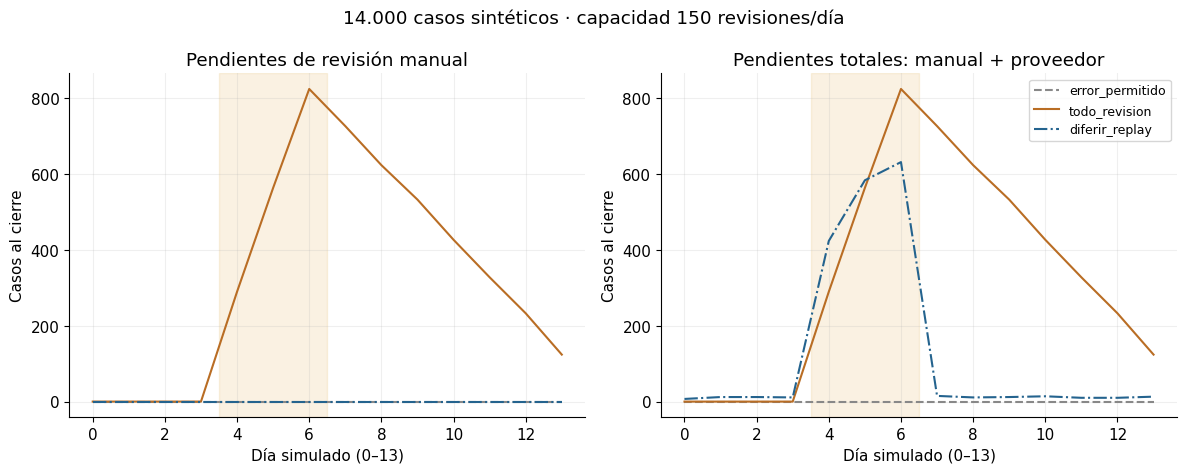

In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8),sharex=True)
styles={"error_permitido":("#888888","--"),"todo_revision":("#b96d24","-"),"diferir_replay":("#24638e","-.")}
for policy in policies:
    frame=queue_results[queue_results.policy==policy]
    color,style=styles[policy]
    axes[0].plot(frame.day,frame.manual_queue,label=policy,color=color,ls=style)
    axes[1].plot(frame.day,frame.manual_queue+frame.external_pending,label=policy,color=color,ls=style)
for ax in axes:
    ax.axvspan(3.5,6.5,color="#e7bd70",alpha=.2)
    ax.set(xlabel="Día simulado (0–13)",ylabel="Casos al cierre")
axes[0].set_title("Pendientes de revisión manual")
axes[1].set_title("Pendientes totales: manual + proveedor")
axes[1].legend(fontsize=9)
fig.suptitle("14.000 casos sintéticos · capacidad 150 revisiones/día")
fig.tight_layout();plt.show()

### 12. Medir el intercambio entre espera y verificaciones

Aprobar ante error puede producir cola cero y un control incompleto. Replay genera más llamadas, datos que deben incluirse al estimar costo por reintento y límites del contrato. La resolución de pendientes de este ejemplo depende de recuperarse de la caída; no prueba recuperación frente a una caída permanente.

In [13]:
finals=queue_results.groupby("policy").tail(1).set_index("policy")
assert finals.loc["error_permitido","unverified"]>0
assert summary.loc["todo_revision","peak_manual"]>summary.loc["diferir_replay","peak_manual"]
assert summary.loc["diferir_replay","total_attempts"]>N_CASES
metrics={"joint_escape_independent":float(joint_escape(0)),
         "joint_escape_shared":float(joint_escape(1)),
         "economic_saving_independent_cop":independence_saving,
         "economic_saving_shared_cop":shared_saving,
         "critical_shared_fraction":float(critical_shared),
         "queue_summary":json.loads(summary.to_json(orient="index"))}
print("ACADEMIC_METRICS:"+json.dumps(metrics))

ACADEMIC_METRICS:{"joint_escape_independent": 0.0096, "joint_escape_shared": 0.08, "economic_saving_independent_cop": 1120.682, "economic_saving_shared_cop": -287.31799999999976, "critical_shared_fraction": 0.7959389204545454, "queue_summary": {"diferir_replay": {"peak_manual": 0, "peak_external": 632, "max_wait": 2, "final_unverified": 0, "total_attempts": 15754}, "error_permitido": {"peak_manual": 0, "peak_external": 0, "max_wait": 0, "final_unverified": 1337, "total_attempts": 14000}, "todo_revision": {"peak_manual": 825, "peak_external": 0, "max_wait": 5, "final_unverified": 0, "total_attempts": 14000}}}


### 13. Dimensión de una evaluación sin escapes observados

Si $n$ ataques independientes no presentan escapes, el límite superior unilateral exacto al 95% para la probabilidad de escape es

$$u=1-0.05^{1/n}.$$

La fórmula procede de resolver $(1-u)^n=0.05$, no demuestra seguridad perfecta. Duplicados o familias altamente dependientes invalidan la lectura de $n$ como número de ensayos independientes.

In [14]:
zero_failure_limits=pd.DataFrame({"ataques_independientes":[30,100,300,1000]})
zero_failure_limits["limite_superior_95_pct"]=100*(1-.05**(1/zero_failure_limits.ataques_independientes))
assert 0 < zero_failure_limits.limite_superior_95_pct.iloc[-1] < zero_failure_limits.limite_superior_95_pct.iloc[0]
display(zero_failure_limits.round(3))

,ataques_independientes,limite_superior_95_pct
0,30,9.503
1,100,2.951
2,300,0.994
3,1000,0.299


## Takeaways

- Medir escapes conjuntos: el supuesto de independencia puede sobrestimar el valor de una capa. Mantener el ensayo sobre los mismos ataques, versiones y condiciones de captura.
- Comparar acciones y costo de extremo a extremo. El beneficio del escenario cambia de signo al compartir fallos; no equivale a decidir una compra.
- Registrar revisión manual y espera externa por separado. Cola manual baja puede esconder evidencia pendiente o aprobaciones sin verificar.
- Antes de integración, incorporar eficacia imperfecta, límites de llamadas, costos de demora, múltiples recursos, dependencia de falsos positivos y ataques no vistos.

No se entrenó un modelo de deepfakes ni se integraron proveedores. Las cuatro arquitecturas siguen en diseño. El experimento explica dos supuestos críticos, sin ampliar su evidencia a pérdidas reales.

## Fuentes, fórmulas y reproducción

Las ecuaciones de mezcla, costo, cola y límite binomial se derivan en el cuaderno; no se atribuyen como hallazgos de un paper. Contexto defensivo: [NIST SP 800-63A-4 §3.14](https://pages.nist.gov/800-63-4/sp800-63a.html#DigInject), [FinCEN FIN-2024-Alert004](https://www.fincen.gov/system/files/shared/FinCEN-Alert-DeepFakes-Alert508FINAL.pdf). Investigación publicada: [FaceForensics++, ICCV 2019](https://openaccess.thecvf.com/content_ICCV_2019/papers/Rossler_FaceForensics_Learning_to_Detect_Manipulated_Facial_Images_ICCV_2019_paper.pdf), DOI 10.1109/ICCV.2019.00009, inspira pruebas de manipulación/generalización; [CARE-GNN, CIKM 2020](https://penghao-bdsc.github.io/papers/cikm20.pdf), DOI 10.1145/3340531.3411903, inspira camuflaje de relaciones. **No se replican esos dos papers aquí** ni se evalúa una herramienta nueva de fraude con sus datasets.

Desde raíz del repositorio: ejecutar `python <esta_carpeta>/build_notebook.py`, después `python scripts/execute_research_depth.py --one <esta_carpeta>/notebook.ipynb --mode kernel --result <esta_carpeta>/evidence/execution.json`. En el entorno local restringido se usa `--mode ipython` en un proceso nuevo; CI puede usar kernel. Las dependencias directas están en requirements.txt; no constituyen un lock transitivo completo. El generador borra outputs al regenerar: ejecutar de nuevo antes de publicar.